
# PhytoFactor-HPCTR
## Main
- **Taxonomy-consistent 115-class fusion:** host and disease heads now provide a bounded learnable prior to combination logits.
- **Layer-wise LR decay (LLRD):** lower learning rates for early pretrained ConvNeXt layers.
- **EMA validation/checkpointing:** exponential moving-average weights are used for validation and the primary test result.
- **Metric-aligned lesion loss:** Dice + Focal + low-resolution Lovász hinge + boundary Dice.
- **Uncertainty-gated coverage fusion:** mask-derived coverage is fused with a direct continuous estimate instead of the old fixed ±15% residual correction.
- **Coverage-preserving 90° augmentation:** more geometry diversity without changing lesion coverage after square resize

In [1]:
# 1. Imports and reproducibility
import os, re, gc, math, time, json, random, warnings, copy
from pathlib import Path
from dataclasses import dataclass, asdict
from collections import defaultdict

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             mean_absolute_error, mean_squared_error, r2_score)
from scipy.stats import pearsonr, spearmanr
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode

warnings.filterwarnings('ignore')
torch.backends.cudnn.benchmark=True
try:
    torch.set_float32_matmul_precision('high')
except Exception:
    pass

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything(42)
print('PyTorch:',torch.__version__,flush=True)
print('CUDA:',torch.cuda.is_available(),flush=True)
if torch.cuda.is_available():
    print('Visible GPUs:',torch.cuda.device_count(),flush=True)
    for gi in range(torch.cuda.device_count()):
        print(f'  GPU {gi}: {torch.cuda.get_device_name(gi)}',flush=True)


PyTorch: 2.10.0+cu128
CUDA: True
Visible GPUs: 2
  GPU 0: Tesla T4
  GPU 1: Tesla T4


In [2]:
# 2. Configuration
@dataclass
class CFG:
    seed:int=42
    image_size:int=512
    epochs:int=34
    batch_size:int=2
    grad_accum:int=2
    num_workers:int=4
    prefetch_factor:int=2
    pretrained:bool=True

    backbone_lr:float=3e-5
    head_lr:float=3e-4
    layer_decay:float=0.80
    weight_decay:float=0.05
    warmup_epochs:int=2
    min_lr_ratio:float=0.04
    grad_clip:float=1.0

    fpn_dim:int=128
    embed_dim:int=256
    dropout:float=0.20

    ema_decay:float=0.9995
    ema_warmup_tau:float=2000.0
    label_smoothing:float=0.03
    lovasz_downsample:int=256

    patience:int=9
    progress_every:int=20
    output_dir:str='/kaggle/working/phytofactor_hpctr_v2_results'

    w_combo:float=1.00
    w_host:float=0.20
    w_disease:float=0.20
    w_taxonomy:float=0.10
    w_prototype:float=0.30
    w_seg:float=1.55
    w_factorized:float=0.45
    w_severity:float=0.50
    w_consistency:float=0.08

    hflip_p:float=0.50
    vflip_p:float=0.10
    rot90_p:float=0.25
    color_jitter_p:float=0.70

cfg=CFG(); seed_everything(cfg.seed)
DEVICE=torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
AMP_ENABLED=DEVICE.type=='cuda'
Path(cfg.output_dir).mkdir(parents=True,exist_ok=True)
print(json.dumps(asdict(cfg),indent=2),flush=True)
print('Device:',DEVICE,flush=True)
print('Effective batch size:',cfg.batch_size*cfg.grad_accum,flush=True)


{
  "seed": 42,
  "image_size": 512,
  "epochs": 34,
  "batch_size": 2,
  "grad_accum": 2,
  "num_workers": 4,
  "prefetch_factor": 2,
  "pretrained": true,
  "backbone_lr": 3e-05,
  "head_lr": 0.0003,
  "layer_decay": 0.8,
  "weight_decay": 0.05,
  "warmup_epochs": 2,
  "min_lr_ratio": 0.04,
  "grad_clip": 1.0,
  "fpn_dim": 128,
  "embed_dim": 256,
  "dropout": 0.2,
  "ema_decay": 0.9995,
  "ema_warmup_tau": 2000.0,
  "label_smoothing": 0.03,
  "lovasz_downsample": 256,
  "patience": 9,
  "progress_every": 20,
  "output_dir": "/kaggle/working/phytofactor_hpctr_v2_results",
  "w_combo": 1.0,
  "w_host": 0.2,
  "w_disease": 0.2,
  "w_taxonomy": 0.1,
  "w_prototype": 0.3,
  "w_seg": 1.55,
  "w_factorized": 0.45,
  "w_severity": 0.5,
  "w_consistency": 0.08,
  "hflip_p": 0.5,
  "vflip_p": 0.1,
  "rot90_p": 0.25,
  "color_jitter_p": 0.7
}
Device: cuda:0
Effective batch size: 4


In [3]:

# 3. Official PlantSeg 115-combination taxonomy
COMBO_NAMES = [
'apple black rot','apple mosaic virus','apple rust','apple scab',
'banana anthracnose','banana black leaf streak','banana bunchy top','banana cigar end rot','banana cordana leaf spot','banana panama disease',
'basil downy mildew','bean halo blight','bean mosaic virus','bean rust',
'bell pepper bacterial spot','bell pepper blossom end rot','bell pepper frogeye leaf spot','bell pepper powdery mildew',
'blueberry anthracnose','blueberry botrytis blight','blueberry mummy berry','blueberry rust','blueberry scorch',
'broccoli alternaria leaf spot','broccoli downy mildew','broccoli ring spot','cabbage alternaria leaf spot','cabbage black rot','cabbage downy mildew',
'carrot alternaria leaf blight','carrot cavity spot','carrot cercospora leaf blight','cauliflower alternaria leaf spot','cauliflower bacterial soft rot',
'celery anthracnose','celery early blight','cherry leaf spot','cherry powdery mildew','citrus canker','citrus greening disease',
'coffee berry blotch','coffee black rot','coffee brown eye spot','coffee leaf rust','corn gray leaf spot','corn northern leaf blight','corn rust','corn smut',
'cucumber angular leaf spot','cucumber bacterial wilt','cucumber powdery mildew','eggplant cercospora leaf spot','eggplant phomopsis fruit rot','eggplant phytophthora blight',
'garlic leaf blight','garlic rust','ginger leaf spot','ginger sheath blight','grape black rot','grape downy mildew','grape leaf spot','grapevine leafroll disease',
'lettuce downy mildew','lettuce mosaic virus','maple tar spot','peach anthracnose','peach brown rot','peach leaf curl','peach rust','peach scab',
'plum bacterial spot','plum brown rot','plum pocket disease','plum pox virus','plum rust','potato early blight','potato late blight',
'raspberry fire blight','raspberry gray mold','raspberry leaf spot','raspberry yellow rust','rice blast','rice sheath blight',
'soybean bacterial blight','soybean brown spot','soybean downy mildew','soybean frog eye leaf spot','soybean mosaic','soybean rust','squash powdery mildew',
'strawberry anthracnose','strawberry leaf scorch','tobacco blue mold','tobacco brown spot','tobacco frogeye leaf spot','tobacco mosaic virus',
'tomato bacterial leaf spot','tomato early blight','tomato late blight','tomato leaf mold','tomato mosaic virus','tomato septoria leaf spot','tomato yellow leaf curl virus',
'wheat bacterial leaf streak (black chaff)','wheat head scab','wheat leaf rust','wheat loose smut','wheat powdery mildew','wheat septoria blotch','wheat stem rust','wheat stripe rust',
'zucchini bacterial wilt','zucchini downy mildew','zucchini powdery mildew','zucchini yellow mosaic virus']
assert len(COMBO_NAMES) == 115

def split_combo_taxonomy(combo):
    if combo.startswith('bell pepper '):
        host='bell pepper'; disease=combo[len('bell pepper '):]
    elif combo.startswith('grapevine '):
        host='grape'; disease=combo[len('grapevine '):]
    else:
        host=combo.split()[0]; disease=combo[len(host)+1:]
    disease=disease.replace('frog eye','frogeye')
    return host,disease

combo_tax=[split_combo_taxonomy(x) for x in COMBO_NAMES]
HOST_NAMES=sorted({h for h,d in combo_tax})
DISEASE_NAMES=sorted({d for h,d in combo_tax})
assert len(HOST_NAMES)==34
assert len(DISEASE_NAMES)==69
host_to_idx={x:i for i,x in enumerate(HOST_NAMES)}
disease_to_idx={x:i for i,x in enumerate(DISEASE_NAMES)}
COMBO_TO_HOST=torch.tensor([host_to_idx[h] for h,d in combo_tax],dtype=torch.long)
COMBO_TO_DISEASE=torch.tensor([disease_to_idx[d] for h,d in combo_tax],dtype=torch.long)
print(len(COMBO_NAMES), len(HOST_NAMES), len(DISEASE_NAMES))


115 34 69


In [4]:
# 4. Set PlantSegV2 dataset path manually

from pathlib import Path
import re

IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

# Exact Kaggle dataset path
DATA_ROOT = Path("/kaggle/input/datasets/weitianqi/plantseg/plantsegv2")

if not DATA_ROOT.exists():
    raise FileNotFoundError(f"Dataset path not found: {DATA_ROOT}")

print("DATA_ROOT:", DATA_ROOT)


def norm_key(s):
    return re.sub(r'[^a-z0-9]+', '_', str(s).lower()).strip('_')


COMBO_SLUGS = sorted(
    [(i, norm_key(n)) for i, n in enumerate(COMBO_NAMES)],
    key=lambda x: len(x[1]),
    reverse=True
)


def infer_combo_from_filename(filename):
    stem = norm_key(Path(filename).stem)

    for idx, slug in COMBO_SLUGS:
        if stem == slug or stem.startswith(slug + '_'):
            return idx

    return None


def split_dir(parent, split):
    p = DATA_ROOT / parent / split

    if not p.exists():
        raise FileNotFoundError(f"Folder not found: {p}")

    return p


# Check dataset structure
print("\nDataset folders:")
for item in DATA_ROOT.iterdir():
    print(" -", item.name)

print("\nSplit paths:")
for split in ['train', 'val', 'test']:
    print(f"{split} images      :", split_dir('images', split))
    print(f"{split} annotations :", split_dir('annotations', split))

DATA_ROOT: /kaggle/input/datasets/weitianqi/plantseg/plantsegv2

Dataset folders:
 - Metadatav2.csv
 - annotations
 - images
 - coco_annotations.json

Split paths:
train images      : /kaggle/input/datasets/weitianqi/plantseg/plantsegv2/images/train
train annotations : /kaggle/input/datasets/weitianqi/plantseg/plantsegv2/annotations/train
val images      : /kaggle/input/datasets/weitianqi/plantseg/plantsegv2/images/val
val annotations : /kaggle/input/datasets/weitianqi/plantseg/plantsegv2/annotations/val
test images      : /kaggle/input/datasets/weitianqi/plantseg/plantsegv2/images/test
test annotations : /kaggle/input/datasets/weitianqi/plantseg/plantsegv2/annotations/test


In [5]:

# 5. Exact image-mask index + robust raw mask decoding

def infer_combo_from_mask_file(mask_path):
    a=np.array(Image.open(mask_path)); vals=np.unique(a)
    nz=[int(v) for v in vals if 1<=int(v)<=115]
    if len(nz)==1 and 0 in vals: return nz[0]-1
    cand=[int(v) for v in vals if 0<=int(v)<=114]
    if len(cand)==1 and 255 in vals: return cand[0]
    return None

def build_split_index(split):
    imgs=[p for p in split_dir('images',split).rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTS]
    masks=[p for p in split_dir('annotations',split).rglob('*.png')]
    mask_by_stem={p.stem:p for p in masks}
    rows=[]; missing=[]; unresolved=[]
    for ip in sorted(imgs):
        mp=mask_by_stem.get(ip.stem)
        if mp is None: missing.append(ip.name); continue
        combo=infer_combo_from_filename(ip.name)
        if combo is None: combo=infer_combo_from_mask_file(mp)
        if combo is None: unresolved.append(ip.name); continue
        h=int(COMBO_TO_HOST[combo]); d=int(COMBO_TO_DISEASE[combo])
        rows.append(dict(split=split,filename=ip.name,image_path=str(ip),mask_path=str(mp),combo=combo,
                         host=h,disease=d,combo_name=COMBO_NAMES[combo],host_name=HOST_NAMES[h],disease_name=DISEASE_NAMES[d]))
    print(f'{split}: paired={len(rows)} missing_mask={len(missing)} unresolved={len(unresolved)}')
    if unresolved[:5]: print('unresolved examples:',unresolved[:5])
    return pd.DataFrame(rows)

train_df=build_split_index('train'); val_df=build_split_index('val'); test_df=build_split_index('test')
assert len(train_df)>0 and len(val_df)>0 and len(test_df)>0
assert train_df.combo.nunique()>100, 'Too few classes recovered.'
display(pd.DataFrame({'split':['train','val','test'],'images':[len(train_df),len(val_df),len(test_df)],
                      'classes':[train_df.combo.nunique(),val_df.combo.nunique(),test_df.combo.nunique()]}))
display(train_df.groupby('combo_name').size().sort_values().rename('n').to_frame().head(15))

def mask_to_binary(arr,combo_idx):
    arr=np.asarray(arr); vals=set(np.unique(arr).astype(int).tolist())
    if 0 in vals and (combo_idx+1) in vals: return (arr==(combo_idx+1)).astype(np.uint8)
    if 255 in vals and combo_idx in vals: return (arr==combo_idx).astype(np.uint8)
    if vals.issubset({0,255}): return (arr==255).astype(np.uint8)
    pos=(arr!=0)
    if 255 in vals: pos=(arr!=0)&(arr!=255)
    return pos.astype(np.uint8)

check=[]
for _,r in train_df.sample(min(20,len(train_df)),random_state=cfg.seed).iterrows():
    raw=np.array(Image.open(r.mask_path)); b=mask_to_binary(raw,int(r.combo))
    check.append((r.filename,r.combo_name,np.unique(raw).tolist()[:8],float(b.mean())))
display(pd.DataFrame(check,columns=['file','combo','raw_values','lesion_ratio']))
assert max(x[3] for x in check)>0


train: paired=7916 missing_mask=0 unresolved=0
val: paired=1247 missing_mask=0 unresolved=0
test: paired=2295 missing_mask=0 unresolved=0


,split,images,classes
0,train,7916,115
1,val,1247,115
2,test,2295,115


,n
combo_name,
coffee black rot,5
peach rust,5
peach anthracnose,8
broccoli ring spot,11
plum bacterial spot,11
raspberry leaf spot,13
coffee brown eye spot,13
carrot cercospora leaf blight,13
ginger leaf spot,17


,file,combo,raw_values,lesion_ratio
0,strawberry_anthracnose_google_0037.jpg,strawberry anthracnose,"[0, 91]",0.016189
1,squash_powdery_mildew_google_0213.jpg,squash powdery mildew,"[0, 90]",0.850393
2,cauliflower_alternaria_leaf_spot_146.jpg,cauliflower alternaria leaf spot,"[0, 33]",0.418815
3,citrus_canker_288.jpg,citrus canker,"[0, 39]",0.071666
4,cucumber_bacterial_wilt_3.jpg,cucumber bacterial wilt,"[0, 50]",0.100087
5,tomato_septoria_leaf_spot_google_0004.jpg,tomato septoria leaf spot,"[0, 102]",0.178319
6,wheat_septoria_blotch_blotch (94).jpg,wheat septoria blotch,"[0, 109]",0.102808
7,coffee_leaf_rust_google_0208.jpg,coffee leaf rust,"[0, 44]",0.040631
8,potato_early_blight_14.jpg,potato early blight,"[0, 76]",0.091451
9,corn_gray_leaf_spot_google_0002.jpg,corn gray leaf spot,"[0, 45]",0.159596


In [6]:
# 6. Dataset and coverage-preserving augmentation
IMAGENET_MEAN=[0.485,0.456,0.406]; IMAGENET_STD=[0.229,0.224,0.225]

class PlantSegMTLDataset(Dataset):
    def __init__(self,df,train=False): self.df=df.reset_index(drop=True); self.train=train
    def __len__(self): return len(self.df)
    def __getitem__(self,idx):
        r=self.df.iloc[idx]
        image=Image.open(r.image_path).convert('RGB')
        raw=np.array(Image.open(r.mask_path)); binary=mask_to_binary(raw,int(r.combo))
        severity=float(binary.mean())
        mask=Image.fromarray((binary*255).astype(np.uint8),mode='L')

        image=TF.resize(image,[cfg.image_size,cfg.image_size],interpolation=InterpolationMode.BILINEAR,antialias=True)
        mask=TF.resize(mask,[cfg.image_size,cfg.image_size],interpolation=InterpolationMode.NEAREST)

        if self.train:
            if random.random()<cfg.hflip_p: image,mask=TF.hflip(image),TF.hflip(mask)
            if random.random()<cfg.vflip_p: image,mask=TF.vflip(image),TF.vflip(mask)
            if random.random()<cfg.rot90_p:
                angle=90*random.choice([1,2,3])
                image=TF.rotate(image,angle,interpolation=InterpolationMode.BILINEAR)
                mask=TF.rotate(mask,angle,interpolation=InterpolationMode.NEAREST)
            if random.random()<cfg.color_jitter_p:
                image=TF.adjust_brightness(image,random.uniform(.87,1.13))
                image=TF.adjust_contrast(image,random.uniform(.87,1.13))
                image=TF.adjust_saturation(image,random.uniform(.87,1.13))
                image=TF.adjust_hue(image,random.uniform(-.025,.025))

        image=TF.normalize(TF.to_tensor(image),IMAGENET_MEAN,IMAGENET_STD)
        mask=(TF.pil_to_tensor(mask).float()/255.0>0.5).float()
        return {'image':image,'mask':mask,'combo':torch.tensor(int(r.combo),dtype=torch.long),
                'host':torch.tensor(int(r.host),dtype=torch.long),'disease':torch.tensor(int(r.disease),dtype=torch.long),
                'severity':torch.tensor(severity,dtype=torch.float32),'filename':r.filename}

train_ds=PlantSegMTLDataset(train_df,True); val_ds=PlantSegMTLDataset(val_df,False); test_ds=PlantSegMTLDataset(test_df,False)
loader_args=dict(num_workers=cfg.num_workers,pin_memory=AMP_ENABLED,persistent_workers=cfg.num_workers>0)
if cfg.num_workers>0: loader_args['prefetch_factor']=cfg.prefetch_factor
train_loader=DataLoader(train_ds,batch_size=cfg.batch_size,shuffle=True,drop_last=True,**loader_args)
val_loader=DataLoader(val_ds,batch_size=cfg.batch_size,shuffle=False,**loader_args)
test_loader=DataLoader(test_ds,batch_size=cfg.batch_size,shuffle=False,**loader_args)
b=next(iter(train_loader))
print('train batches/epoch:',len(train_loader),flush=True)
print('val batches/epoch  :',len(val_loader),flush=True)
print('test batches       :',len(test_loader),flush=True)
print('image:',b['image'].shape,'mask:',b['mask'].shape,flush=True)
print('severity range:',b['severity'].min().item(),'to',b['severity'].max().item(),flush=True)


train batches/epoch: 3958
val batches/epoch  : 624
test batches       : 1148
image: torch.Size([2, 3, 512, 512]) mask: torch.Size([2, 1, 512, 512])
severity range: 0.04703111574053764 to 0.22595316171646118


In [7]:

# 7. Moderate long-tail class weights

def effective_num_weights(labels,n_classes,beta=.999,clip=(.35,5.0)):
    counts=np.bincount(np.asarray(labels,dtype=int),minlength=n_classes).astype(np.float64)
    cs=np.maximum(counts,1.0)
    w=(1-beta)/(1-np.power(beta,cs)); w=w/w.mean(); w=np.clip(w,*clip)
    return torch.tensor(w,dtype=torch.float32),counts

combo_w,combo_counts=effective_num_weights(train_df.combo.values,115)
host_w,host_counts=effective_num_weights(train_df.host.values,34)
disease_w,disease_counts=effective_num_weights(train_df.disease.values,69)
combo_w=combo_w.to(DEVICE); host_w=host_w.to(DEVICE); disease_w=disease_w.to(DEVICE)
print('combo train count min/median/max:',int(combo_counts.min()),float(np.median(combo_counts)),int(combo_counts.max()))


combo train count min/median/max: 5 53.0 271


In [8]:
# 7.5 Dataset diagnostics
imbalance_factor=float(combo_counts.max()/max(combo_counts.min(),1))
print(f'Class imbalance factor: {combo_counts.max():.0f}/{combo_counts.min():.0f} = {imbalance_factor:.2f}x',flush=True)
meta_path=DATA_ROOT/'Metadatav2.csv'
if meta_path.exists():
    meta=pd.read_csv(meta_path)
    print('Metadata rows:',len(meta),flush=True)
    print('Metadata columns:',list(meta.columns),flush=True)
    norm_cols={re.sub(r'[^a-z0-9]','',c.lower()):c for c in meta.columns}
    ratio_col=next((v for k,v in norm_cols.items() if 'maskratio' in k),None)
    if ratio_col is not None:
        vals=pd.to_numeric(meta[ratio_col],errors='coerce').dropna()
        if len(vals): print(f'Mask-ratio stats: mean={vals.mean():.4f}, median={vals.median():.4f}, min={vals.min():.4f}, max={vals.max():.4f}',flush=True)


Class imbalance factor: 271/5 = 54.20x
Metadata rows: 11458
Metadata columns: ['Name', 'Index', 'Plant', 'Disease', 'Resolution', 'Label file', 'Mask ratio', 'URL', 'Split']
Mask-ratio stats: mean=0.2136, median=0.1366, min=0.0000, max=1.0000


## Proposed architecture — HPCTR

### Taxonomy-consistent recognition
The 115-class combination score receives a bounded learned prior from the host and disease heads:

\[
z_c^{final}=z_c^{combo}+\alpha[\log p(h(c))+\log p(d(c))]
\]

### Uncertainty-gated coverage fusion
The lesion mask gives spatial coverage \(r_{mask}\) and uncertainty \(u=\mathbb{E}[4p(1-p)]\). A direct scalar estimate \(r_{direct}\) is fused with mask coverage using a learned gate:

\[
\hat r=g\,r_{mask}+(1-g)\,r_{direct}.
\]

This specifically removes the old ±15% residual correction ceiling that could not recover from large mask-coverage errors.


In [ ]:
# 8. PhytoFactor-HPCTR
class ConvGNAct(nn.Module):
    def __init__(self,cin,cout):
        super().__init__(); g=8 if cout%8==0 else 1
        self.block=nn.Sequential(nn.Conv2d(cin,cout,3,padding=1,bias=False),nn.GroupNorm(g,cout),nn.GELU())
    def forward(self,x): return self.block(x)

class HPCTRBlock(nn.Module):
    def __init__(self,channels,proto_dim):
        super().__init__(); hidden=max(channels,128)
        self.proto_to_channel=nn.Sequential(nn.Linear(proto_dim,channels),nn.GELU())
        self.router=nn.Sequential(nn.Linear(channels*2,hidden),nn.GELU(),nn.Linear(hidden,channels*3))
        self.id_to_lesion=nn.Conv2d(channels,channels,1,bias=False)
        self.lesion_to_severity=nn.Conv2d(channels,channels,1,bias=False)
        g=8 if channels%8==0 else 1
        self.lesion_norm=nn.GroupNorm(g,channels); self.severity_norm=nn.GroupNorm(g,channels)
        self.alpha_id_to_lesion=nn.Parameter(torch.tensor(-2.0)); self.alpha_lesion_to_severity=nn.Parameter(torch.tensor(-2.0))
    def forward(self,feature,soft_proto):
        b,c,_,_=feature.shape
        feat_context=F.adaptive_avg_pool2d(feature,1).flatten(1); proto_context=self.proto_to_channel(soft_proto)
        route_logits=self.router(torch.cat([feat_context,proto_context],1)).view(b,3,c,1,1)
        route_weights=F.softmax(route_logits,dim=1)
        identity_route=feature*route_weights[:,0]; lesion_base=feature*route_weights[:,1]; severity_base=feature*route_weights[:,2]
        proto_gate=torch.sigmoid(proto_context)[:,:,None,None]
        alpha=torch.sigmoid(self.alpha_id_to_lesion); beta=torch.sigmoid(self.alpha_lesion_to_severity)
        lesion_route=self.lesion_norm(feature+lesion_base+alpha*self.id_to_lesion(identity_route)*proto_gate)
        severity_route=self.severity_norm(feature+severity_base+beta*self.lesion_to_severity(lesion_route))
        return identity_route,lesion_route,severity_route,route_weights

class PhytoFactorHPCTRv2(nn.Module):
    def __init__(self):
        super().__init__()
        if cfg.pretrained:
            try:
                base=convnext_tiny(weights=ConvNeXt_Tiny_Weights.IMAGENET1K_V1); print('Loaded pretrained ConvNeXt-Tiny',flush=True)
            except Exception as e: raise RuntimeError('Enable Kaggle Internet so ImageNet weights can download. '+str(e))
        else: base=convnext_tiny(weights=None)
        self.backbone=base.features; self.stage_ids={1,3,5,7}; channels=[96,192,384,768]
        self.register_buffer('combo_to_host',COMBO_TO_HOST.clone(),persistent=False)
        self.register_buffer('combo_to_disease',COMBO_TO_DISEASE.clone(),persistent=False)
        self.embed=nn.Sequential(nn.LayerNorm(768),nn.Linear(768,cfg.embed_dim),nn.GELU(),nn.Dropout(cfg.dropout))
        self.combo_head=nn.Linear(cfg.embed_dim,115); self.host_head=nn.Linear(cfg.embed_dim,34); self.disease_head=nn.Linear(cfg.embed_dim,69)
        self.taxonomy_gate_logit=nn.Parameter(torch.tensor(-1.5))
        self.prototypes=nn.Parameter(torch.randn(115,cfg.embed_dim)*.02); self.proto_scale=nn.Parameter(torch.tensor(math.log(10.0)))
        self.lateral=nn.ModuleList([nn.Conv2d(c,cfg.fpn_dim,1) for c in channels])
        self.hpctr=nn.ModuleList([HPCTRBlock(cfg.fpn_dim,cfg.embed_dim) for _ in range(4)])
        self.identity_refine=nn.Sequential(nn.Linear(cfg.fpn_dim,cfg.embed_dim),nn.GELU(),nn.Dropout(cfg.dropout),nn.Linear(cfg.embed_dim,115))
        self.smooth=nn.ModuleList([ConvGNAct(cfg.fpn_dim,cfg.fpn_dim) for _ in range(4)])
        self.seg_head=nn.Sequential(ConvGNAct(cfg.fpn_dim,96),ConvGNAct(96,64),nn.Conv2d(64,1,1))
        self.severity_context=nn.Sequential(nn.Linear(cfg.fpn_dim*4,cfg.embed_dim),nn.GELU(),nn.Dropout(cfg.dropout))
        severity_in=cfg.embed_dim*3+2
        self.direct_severity_head=nn.Sequential(nn.Linear(severity_in,256),nn.GELU(),nn.Dropout(cfg.dropout),nn.Linear(256,64),nn.GELU(),nn.Linear(64,1))
        self.severity_gate_head=nn.Sequential(nn.Linear(severity_in,128),nn.GELU(),nn.Linear(128,1))
        nn.init.constant_(self.severity_gate_head[-1].bias,0.85)
    def features(self,x):
        outs=[]
        for idx,layer in enumerate(self.backbone):
            x=layer(x)
            if idx in self.stage_ids: outs.append(x)
        return outs
    def forward(self,x):
        hw=x.shape[-2:]; c1,c2,c3,c4=self.features(x)
        z=self.embed(F.adaptive_avg_pool2d(c4,1).flatten(1)); zn=F.normalize(z,dim=1); pn=F.normalize(self.prototypes,dim=1)
        proto_logits=(zn@pn.t())*self.proto_scale.exp().clamp(1,50)
        host_logits=self.host_head(z); disease_logits=self.disease_head(z)
        host_logp=F.log_softmax(host_logits,dim=1); disease_logp=F.log_softmax(disease_logits,dim=1)
        taxonomy_prior=.5*(host_logp[:,self.combo_to_host]+disease_logp[:,self.combo_to_disease])
        taxonomy_gate=.35*torch.sigmoid(self.taxonomy_gate_logit)
        base_combo_logits=self.combo_head(z)+.5*proto_logits+taxonomy_gate*taxonomy_prior
        soft_proto=F.softmax(base_combo_logits,dim=1)@pn
        projected=[m(c) for m,c in zip(self.lateral,[c1,c2,c3,c4])]
        ids=[]; lesions=[]; severities=[]; rws=[]
        for feat,router in zip(projected,self.hpctr):
            rid,rles,rsev,rw=router(feat,soft_proto); ids.append(rid); lesions.append(rles); severities.append(rsev); rws.append(rw)
        id_global=F.adaptive_avg_pool2d(ids[-1],1).flatten(1)
        combo_logits=base_combo_logits+.25*self.identity_refine(id_global)
        refined_soft_proto=F.softmax(combo_logits,dim=1)@pn
        l1,l2,l3,l4=lesions
        p4=self.smooth[3](l4)
        p3=self.smooth[2](l3+F.interpolate(p4,size=l3.shape[-2:],mode='bilinear',align_corners=False))
        p2=self.smooth[1](l2+F.interpolate(p3,size=l2.shape[-2:],mode='bilinear',align_corners=False))
        p1=self.smooth[0](l1+F.interpolate(p2,size=l1.shape[-2:],mode='bilinear',align_corners=False))
        lesion_logits=F.interpolate(self.seg_head(p1),size=hw,mode='bilinear',align_corners=False)
        lesion_prob=torch.sigmoid(lesion_logits); coverage=lesion_prob.mean((1,2,3)); uncertainty=(4*lesion_prob*(1-lesion_prob)).mean((1,2,3))
        sev_context=self.severity_context(torch.cat([F.adaptive_avg_pool2d(s,1).flatten(1) for s in severities],1))
        sev_input=torch.cat([z,refined_soft_proto,sev_context,coverage.detach()[:,None],uncertainty.detach()[:,None]],1)
        direct_severity=torch.sigmoid(self.direct_severity_head(sev_input).squeeze(1))
        severity_gate=torch.sigmoid(self.severity_gate_head(sev_input).squeeze(1))
        severity=severity_gate*coverage.detach()+(1-severity_gate)*direct_severity
        route_usage=torch.stack([rw.mean((0,2,3,4)) for rw in rws]).mean(0)
        return dict(combo_logits=combo_logits,proto_logits=proto_logits,host_logits=host_logits,disease_logits=disease_logits,
                    lesion_logits=lesion_logits,mask_coverage=coverage,mask_uncertainty=uncertainty,direct_severity=direct_severity,
                    severity_gate=severity_gate,severity=severity,taxonomy_gate=taxonomy_gate,route_usage=route_usage)

model=PhytoFactorHPCTRv2().to(DEVICE)
print('Parameters M:',sum(p.numel() for p in model.parameters())/1e6,flush=True)
model.eval()
with torch.no_grad():
    x=torch.randn(1,3,cfg.image_size,cfg.image_size,device=DEVICE); o=model(x)
    print(o['combo_logits'].shape,o['lesion_logits'].shape,o['severity'].shape,flush=True)
    print('initial taxonomy gate:',float(o['taxonomy_gate'].cpu()),flush=True)
    print('initial route usage:',o['route_usage'].cpu().numpy(),flush=True)
del x,o; gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()


Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 196MB/s] 


Loaded pretrained ConvNeXt-Tiny
Parameters M: 30.145466
torch.Size([1, 115]) torch.Size([1, 1, 512, 512]) torch.Size([1])
initial taxonomy gate: 0.06384893506765366
initial route usage: [0.33336633 0.3339782  0.33265543]


In [10]:
# 9. Refined losses
def dice_loss(logits,target,eps=1e-6):
    p=torch.sigmoid(logits); inter=(p*target).sum((1,2,3)); den=p.sum((1,2,3))+target.sum((1,2,3))
    return (1-(2*inter+eps)/(den+eps)).mean()

def focal_loss(logits,target,alpha=.75,gamma=2):
    bce=F.binary_cross_entropy_with_logits(logits,target,reduction='none'); p=torch.sigmoid(logits)
    pt=p*target+(1-p)*(1-target); at=alpha*target+(1-alpha)*(1-target)
    return (at*(1-pt).pow(gamma)*bce).mean()

def lovasz_grad(gt_sorted):
    p=len(gt_sorted); gts=gt_sorted.sum(); intersection=gts-gt_sorted.float().cumsum(0); union=gts+(1-gt_sorted.float()).cumsum(0)
    jaccard=1-intersection/union.clamp_min(1e-7)
    if p>1: jaccard[1:p]=jaccard[1:p]-jaccard[:-1]
    return jaccard

def lovasz_hinge_flat(logits,labels):
    if logits.numel()==0: return logits.sum()*0
    labels=labels.float(); signs=2*labels-1; errors=1-logits*signs
    errors_sorted,perm=torch.sort(errors,descending=True); gt_sorted=labels[perm.detach()]
    return torch.dot(F.relu(errors_sorted),lovasz_grad(gt_sorted))

def lovasz_hinge_loss(logits,target,downsample=256):
    logits_ds=F.interpolate(logits,size=(downsample,downsample),mode='bilinear',align_corners=False)
    target_ds=F.interpolate(target,size=(downsample,downsample),mode='nearest')
    return torch.stack([lovasz_hinge_flat(l.reshape(-1),t.reshape(-1)) for l,t in zip(logits_ds,target_ds)]).mean()

def boundary_dice_loss(logits,target,k=3,eps=1e-6):
    p=torch.sigmoid(logits)
    pe=(F.max_pool2d(p,k,1,k//2)+F.max_pool2d(-p,k,1,k//2)).clamp(0,1)
    te=(F.max_pool2d(target,k,1,k//2)+F.max_pool2d(-target,k,1,k//2)).clamp(0,1)
    inter=(pe*te).sum((1,2,3)); den=pe.sum((1,2,3))+te.sum((1,2,3))
    return (1-(2*inter+eps)/(den+eps)).mean()

def js(p,q,eps=1e-7):
    p=p.clamp_min(eps); q=q.clamp_min(eps); m=.5*(p+q)
    return .5*((p*(p.log()-m.log())).sum(1).mean()+(q*(q.log()-m.log())).sum(1).mean())

C2H=COMBO_TO_HOST.to(DEVICE); C2D=COMBO_TO_DISEASE.to(DEVICE)
def marginal(prob,mapping,n):
    out=torch.zeros(prob.size(0),n,device=prob.device,dtype=prob.dtype); out.scatter_add_(1,mapping[None].expand(prob.size(0),-1),prob); return out

def compute_loss(out,batch):
    cy=batch['combo'].to(DEVICE,non_blocking=True); hy=batch['host'].to(DEVICE,non_blocking=True); dy=batch['disease'].to(DEVICE,non_blocking=True)
    mask=batch['mask'].to(DEVICE,non_blocking=True); sy=batch['severity'].to(DEVICE,non_blocking=True)
    combo_vec=F.cross_entropy(out['combo_logits'],cy,weight=combo_w,reduction='none',label_smoothing=cfg.label_smoothing); Lc=combo_vec.mean()
    Lh=F.cross_entropy(out['host_logits'],hy,weight=host_w,label_smoothing=cfg.label_smoothing)
    Ld=F.cross_entropy(out['disease_logits'],dy,weight=disease_w,label_smoothing=cfg.label_smoothing)
    Lp=F.cross_entropy(out['proto_logits'],cy,weight=combo_w,label_smoothing=cfg.label_smoothing)
    cp=F.softmax(out['combo_logits'],1); hp=F.softmax(out['host_logits'],1); dp=F.softmax(out['disease_logits'],1)
    Lt=js(hp,marginal(cp,C2H,34))+js(dp,marginal(cp,C2D,69))
    Ldice=dice_loss(out['lesion_logits'],mask); Lfocal=focal_loss(out['lesion_logits'],mask)
    Llovasz=lovasz_hinge_loss(out['lesion_logits'],mask,cfg.lovasz_downsample); Lboundary=boundary_dice_loss(out['lesion_logits'],mask)
    Ls=.40*Ldice+.30*Lfocal+.20*Llovasz+.10*Lboundary
    bce_per=F.binary_cross_entropy_with_logits(out['lesion_logits'],mask,reduction='none').mean((1,2,3)); lesion_frac=mask.mean((1,2,3)).detach()
    Lfactor=(bce_per+lesion_frac*combo_vec).mean()
    Lsev_final=F.smooth_l1_loss(out['severity'],sy,beta=.05); Lsev_direct=F.smooth_l1_loss(out['direct_severity'],sy,beta=.05)
    Lsev=.80*Lsev_final+.20*Lsev_direct
    Lcons=(out['severity_gate'].detach()*torch.abs(out['severity']-out['mask_coverage'].detach())).mean()
    total=(cfg.w_combo*Lc+cfg.w_host*Lh+cfg.w_disease*Ld+cfg.w_taxonomy*Lt+cfg.w_prototype*Lp+
           cfg.w_seg*Ls+cfg.w_factorized*Lfactor+cfg.w_severity*Lsev+cfg.w_consistency*Lcons)
    parts={'total':total.detach(),'combo':Lc.detach(),'host':Lh.detach(),'disease':Ld.detach(),'taxonomy':Lt.detach(),
           'prototype':Lp.detach(),'seg':Ls.detach(),'dice':Ldice.detach(),'focal':Lfocal.detach(),'lovasz':Llovasz.detach(),
           'boundary':Lboundary.detach(),'factorized':Lfactor.detach(),'severity':Lsev.detach(),'consistency':Lcons.detach()}
    return total,parts


In [11]:
# 10. Layer-wise LR decay + cosine schedule + AMP + EMA
def build_param_groups(model):
    groups={}
    for name,p in model.named_parameters():
        if not p.requires_grad: continue
        if name.startswith('backbone.'):
            try: layer_idx=int(name.split('.')[1])
            except Exception: layer_idx=7
            lr=cfg.backbone_lr*(cfg.layer_decay**(7-layer_idx))
        else: lr=cfg.head_lr
        no_decay=(p.ndim<=1 or name.endswith('.bias') or 'prototypes' in name or 'proto_scale' in name or 'gate_logit' in name or 'alpha_' in name)
        wd=0.0 if no_decay else cfg.weight_decay; key=(round(float(lr),12),float(wd))
        groups.setdefault(key,{'params':[],'lr':lr,'weight_decay':wd})['params'].append(p)
    return list(groups.values())

param_groups=build_param_groups(model)
optimizer=torch.optim.AdamW(param_groups,betas=(.9,.999))
steps_per_epoch=math.ceil(len(train_loader)/cfg.grad_accum); total_steps=cfg.epochs*steps_per_epoch; warmup=cfg.warmup_epochs*steps_per_epoch

def lr_factor(step):
    if step<warmup: return max(.05,(step+1)/max(1,warmup))
    p=(step-warmup)/max(1,total_steps-warmup)
    return cfg.min_lr_ratio+(1-cfg.min_lr_ratio)*.5*(1+math.cos(math.pi*min(1,p)))

scheduler=torch.optim.lr_scheduler.LambdaLR(optimizer,lr_lambda=lr_factor)
scaler=torch.amp.GradScaler('cuda',enabled=AMP_ENABLED)

class ModelEMA:
    def __init__(self,model,decay=.9995,warmup_tau=2000.):
        self.ema=copy.deepcopy(model).eval(); self.decay=float(decay); self.warmup_tau=float(warmup_tau); self.updates=0
        for p in self.ema.parameters(): p.requires_grad_(False)
    @torch.no_grad()
    def update(self,model):
        self.updates+=1; d=self.decay*(1-math.exp(-self.updates/self.warmup_tau))
        es=self.ema.state_dict(); ms=model.state_dict()
        for k,ev in es.items():
            mv=ms[k].detach()
            if torch.is_floating_point(ev): ev.mul_(d).add_(mv,alpha=1-d)
            else: ev.copy_(mv)

ema=ModelEMA(model,cfg.ema_decay,cfg.ema_warmup_tau)
print('Optimizer parameter groups:',len(param_groups),flush=True)
print('optimizer steps/epoch:',steps_per_epoch,'total:',total_steps,flush=True)
print('LR min/max:',min(g['lr'] for g in param_groups),max(g['lr'] for g in param_groups),flush=True)


Optimizer parameter groups: 18
optimizer steps/epoch: 1979 total: 67286
LR min/max: 3.1457280000000014e-07 1.4999999999999999e-05


In [12]:
# 10.5 Preflight
print('Running one-batch v2 preflight...',flush=True)
model.train(); optimizer.zero_grad(set_to_none=True); pre_batch=next(iter(train_loader)); pre_x=pre_batch['image'].to(DEVICE,non_blocking=True)
with torch.amp.autocast(device_type=DEVICE.type,enabled=AMP_ENABLED):
    pre_out=model(pre_x); pre_loss,pre_parts=compute_loss(pre_out,pre_batch)
if not torch.isfinite(pre_loss): raise RuntimeError(f'Non-finite preflight loss: {pre_loss.item()}')
scaler.scale(pre_loss).backward(); optimizer.zero_grad(set_to_none=True)
print(f'Preflight PASSED | total loss={pre_loss.item():.4f}',flush=True)
print({k:round(float(v.item()),4) for k,v in pre_parts.items()},flush=True)
print('taxonomy gate:',float(pre_out['taxonomy_gate'].detach().cpu()),flush=True)
print('severity gate mean:',float(pre_out['severity_gate'].mean().detach().cpu()),flush=True)
del pre_batch,pre_x,pre_out,pre_loss; gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()


Running one-batch v2 preflight...
Preflight PASSED | total loss=7.6595
{'total': 7.6595, 'combo': 2.6559, 'host': 3.6835, 'disease': 4.095, 'taxonomy': 0.1097, 'prototype': 5.276, 'seg': 0.7911, 'dice': 0.9193, 'focal': 0.0635, 'lovasz': 1.5317, 'boundary': 0.9796, 'factorized': 0.8974, 'severity': 0.4459, 'consistency': 0.0144}
taxonomy gate: 0.06384893506765366
severity gate mean: 0.6982421875


In [13]:
# 11. Evaluator with optional flip TTA and clear micro/macro binary metrics
@torch.no_grad()
def forward_with_tta(model,x,tta=False):
    if not tta: return model(x)
    views=[(model(x),None),(model(torch.flip(x,[3])),'h'),(model(torch.flip(x,[2])),'v')]
    merged={}
    for key in ['combo_logits','proto_logits','host_logits','disease_logits','severity','direct_severity','severity_gate']:
        merged[key]=torch.stack([o[key] for o,_ in views],0).mean(0)
    masks=[]
    for o,mode in views:
        lm=o['lesion_logits']
        if mode=='h': lm=torch.flip(lm,[3])
        elif mode=='v': lm=torch.flip(lm,[2])
        masks.append(lm)
    merged['lesion_logits']=torch.stack(masks,0).mean(0)
    p=torch.sigmoid(merged['lesion_logits']); merged['mask_coverage']=p.mean((1,2,3)); merged['mask_uncertainty']=(4*p*(1-p)).mean((1,2,3))
    return merged

@torch.no_grad()
def evaluate(model,loader,return_predictions=False,show_progress=False,desc='Evaluate',tta=False):
    model.eval(); yt=[]; yp=[]; yht=[]; yhp=[]; ydt=[]; ydp=[]; st=[]; sp=[]; files=[]; image_ious=[]; image_dices=[]
    conf=torch.zeros((116,116),dtype=torch.int64,device=DEVICE); TP=FP=FN=0.0
    iterator=tqdm(loader,total=len(loader),desc=desc,dynamic_ncols=True,mininterval=.5,leave=False) if show_progress else loader
    for batch in iterator:
        x=batch['image'].to(DEVICE,non_blocking=True); m=batch['mask'].to(DEVICE,non_blocking=True).bool(); cy=batch['combo'].to(DEVICE,non_blocking=True)
        hy=batch['host'].to(DEVICE,non_blocking=True); dy=batch['disease'].to(DEVICE,non_blocking=True)
        with torch.amp.autocast(device_type=DEVICE.type,enabled=AMP_ENABLED): out=forward_with_tta(model,x,tta)
        cp=out['combo_logits'].argmax(1); hp=out['host_logits'].argmax(1); dp=out['disease_logits'].argmax(1); pm=(torch.sigmoid(out['lesion_logits'])>=.5)
        tp=(pm&m).sum((1,2,3)).float(); fp=(pm&~m).sum((1,2,3)).float(); fn=(~pm&m).sum((1,2,3)).float()
        piou=(tp+1e-7)/(tp+fp+fn+1e-7); pdice=(2*tp+1e-7)/(2*tp+fp+fn+1e-7)
        image_ious+=piou.cpu().tolist(); image_dices+=pdice.cpu().tolist(); TP+=tp.sum().item(); FP+=fp.sum().item(); FN+=fn.sum().item()
        gs=m.squeeze(1).long()*(cy[:,None,None]+1); ps=pm.squeeze(1).long()*(cp[:,None,None]+1)
        flat=gs.reshape(-1)*116+ps.reshape(-1); conf+=torch.bincount(flat,minlength=116*116).reshape(116,116)
        yt+=cy.cpu().tolist(); yp+=cp.cpu().tolist(); yht+=hy.cpu().tolist(); yhp+=hp.cpu().tolist(); ydt+=dy.cpu().tolist(); ydp+=dp.cpu().tolist()
        st+=batch['severity'].cpu().tolist(); sp+=out['severity'].float().cpu().tolist(); files+=batch['filename']
    c=conf.cpu().numpy().astype(float); inter=np.diag(c); union=c.sum(1)+c.sum(0)-inter; support=c.sum(1); present=support[1:]>0
    miou=np.mean(inter[1:][present]/np.maximum(union[1:][present],1)); macc=np.mean(inter[1:][present]/np.maximum(support[1:][present],1))
    labs=sorted(set(yt)); hlabs=sorted(set(yht)); dlabs=sorted(set(ydt))
    metrics=dict(combo_accuracy=accuracy_score(yt,yp),combo_macro_f1=f1_score(yt,yp,labels=labs,average='macro',zero_division=0),
                 combo_macro_precision=precision_score(yt,yp,labels=labs,average='macro',zero_division=0),combo_macro_recall=recall_score(yt,yp,labels=labs,average='macro',zero_division=0),
                 host_accuracy=accuracy_score(yht,yhp),host_macro_f1=f1_score(yht,yhp,labels=hlabs,average='macro',zero_division=0),
                 disease_accuracy=accuracy_score(ydt,ydp),disease_macro_f1=f1_score(ydt,ydp,labels=dlabs,average='macro',zero_division=0),
                 binary_iou=TP/max(TP+FP+FN,1),binary_dice=2*TP/max(2*TP+FP+FN,1),binary_precision=TP/max(TP+FP,1),binary_recall=TP/max(TP+FN,1),
                 binary_iou_image_macro=float(np.mean(image_ious)),binary_dice_image_macro=float(np.mean(image_dices)),
                 semantic_miou_disease=float(miou),semantic_macc_disease=float(macc),severity_mae=mean_absolute_error(st,sp),
                 severity_rmse=math.sqrt(mean_squared_error(st,sp)),severity_r2=r2_score(st,sp),
                 severity_pearson=pearsonr(st,sp)[0] if np.std(st)>0 and np.std(sp)>0 else np.nan,
                 severity_spearman=spearmanr(st,sp)[0] if np.std(st)>0 and np.std(sp)>0 else np.nan)
    if not return_predictions: return metrics
    pdf=pd.DataFrame({'filename':files,'true_combo':yt,'pred_combo':yp,'true_name':[COMBO_NAMES[i] for i in yt],'pred_name':[COMBO_NAMES[i] for i in yp],
                      'true_severity':st,'pred_severity':sp,'image_binary_iou':image_ious,'image_binary_dice':image_dices})
    return metrics,pdf,c

def composite_score(m):
    return m['semantic_miou_disease']+.28*m['combo_macro_f1']+.10*m['binary_dice']+.03*max(m['severity_r2'],0)-.18*m['severity_mae']


In [14]:
# 12. LIVE training; EMA model is validated and checkpointed
history=[]; best_score=-1e9; bad=0
best_path=Path(cfg.output_dir)/'best_phytofactor_hpctr_v2_ema.pt'; last_path=Path(cfg.output_dir)/'last_checkpoint_v2.pt'
print(f'Starting v2 training | epochs={cfg.epochs} | train batches={len(train_loader)} | val batches={len(val_loader)}',flush=True)
for epoch in range(1,cfg.epochs+1):
    epoch_start=time.time(); model.train(); optimizer.zero_grad(set_to_none=True); run=defaultdict(float); seen=0
    train_bar=tqdm(enumerate(train_loader,1),total=len(train_loader),desc=f'Train E{epoch:02d}/{cfg.epochs}',dynamic_ncols=True,mininterval=.5,leave=True)
    for step,batch in train_bar:
        x=batch['image'].to(DEVICE,non_blocking=True)
        with torch.amp.autocast(device_type=DEVICE.type,enabled=AMP_ENABLED):
            out=model(x); loss,parts=compute_loss(out,batch); scaled_loss=loss/cfg.grad_accum
        if not torch.isfinite(loss): raise RuntimeError(f'Non-finite loss epoch={epoch} step={step}: {loss.item()}')
        scaler.scale(scaled_loss).backward()
        if step%cfg.grad_accum==0 or step==len(train_loader):
            scaler.unscale_(optimizer); torch.nn.utils.clip_grad_norm_(model.parameters(),cfg.grad_clip)
            scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True); scheduler.step(); ema.update(model)
        bs=x.size(0); seen+=bs
        for k,v in parts.items(): run[k]+=float(v.item())*bs
        if step==1 or step%cfg.progress_every==0 or step==len(train_loader):
            postfix={'loss':f"{run['total']/max(seen,1):.3f}",'cls':f"{run['combo']/max(seen,1):.3f}",'seg':f"{run['seg']/max(seen,1):.3f}",
                     'sev':f"{run['severity']/max(seen,1):.3f}",'ema':str(ema.updates),'lr':f"{max(g['lr'] for g in optimizer.param_groups):.1e}"}
            if torch.cuda.is_available(): postfix['gpuGB']=f"{torch.cuda.memory_allocated(DEVICE)/1024**3:.1f}"
            train_bar.set_postfix(postfix,refresh=True)
    train_losses={f'train_{k}':v/max(seen,1) for k,v in run.items()}
    print(f'\nEpoch {epoch:02d}: validating EMA model...',flush=True)
    vm=evaluate(ema.ema,val_loader,show_progress=True,desc=f'Val EMA E{epoch:02d}/{cfg.epochs}',tta=False); score=composite_score(vm); mins=(time.time()-epoch_start)/60
    ema.ema.eval()
    with torch.no_grad():
        db=next(iter(val_loader)); dx=db['image'][:1].to(DEVICE)
        with torch.amp.autocast(device_type=DEVICE.type,enabled=AMP_ENABLED): dout=ema.ema(dx)
        tax=float(dout['taxonomy_gate'].cpu()); sg=float(dout['severity_gate'].mean().cpu()); ru=dout['route_usage'].cpu().numpy()
    row={'epoch':epoch,**train_losses,**{f'val_{k}':v for k,v in vm.items()},'selection_score':score,'taxonomy_gate':tax,'severity_gate':sg,
         'route_identity':float(ru[0]),'route_lesion':float(ru[1]),'route_severity':float(ru[2]),'minutes':mins}
    history.append(row); pd.DataFrame(history).to_csv(Path(cfg.output_dir)/'training_history_v2.csv',index=False)
    safe_vm={k:float(v) for k,v in vm.items()}
    torch.save({'model':model.state_dict(),'ema_model':ema.ema.state_dict(),'optimizer':optimizer.state_dict(),'scheduler':scheduler.state_dict(),'scaler':scaler.state_dict(),
                'cfg':asdict(cfg),'epoch':int(epoch),'history':history,'best_score':float(best_score),'bad':int(bad),'ema_updates':int(ema.updates)},last_path)
    print('\n'+'='*92+f"\nEPOCH {epoch:02d}/{cfg.epochs} | {mins:.1f} min | EMA validation\n"+
          f"train loss={train_losses['train_total']:.4f}\nval cls accuracy={vm['combo_accuracy']:.4f}\nval macro-F1={vm['combo_macro_f1']:.4f}\n"+
          f"val binary Dice={vm['binary_dice']:.4f}\nval semantic IoU={vm['semantic_miou_disease']:.4f}\nval severity MAE={vm['severity_mae']:.4f}\n"+
          f"val severity R2={vm['severity_r2']:.4f}\ntaxonomy gate={tax:.4f}\nseverity gate={sg:.4f}\n"+'='*92,flush=True)
    if score>best_score:
        best_score=score; bad=0
        torch.save({'model':ema.ema.state_dict(),'raw_model':model.state_dict(),'cfg':asdict(cfg),'epoch':int(epoch),'val_metrics':safe_vm,'best_score':float(best_score),'ema_updates':int(ema.updates)},best_path)
        print(f'✓ saved NEW BEST EMA -> {best_path}',flush=True)
    else:
        bad+=1; print(f'No improvement: {bad}/{cfg.patience}',flush=True)
    if bad>=cfg.patience: print(f'Early stopping at epoch {epoch}',flush=True); break
print('Training complete.',flush=True); print('Best EMA:',best_path,flush=True); print('Last:',last_path,flush=True)


Starting v2 training | epochs=34 | train batches=3958 | val batches=624


Train E01/34:   0%|          | 0/3958 [00:00<?, ?it/s]


Epoch 01: validating EMA model...


Val EMA E01/34:   0%|          | 0/624 [00:00<?, ?it/s]


EPOCH 01/34 | 7.8 min | EMA validation
train loss=6.3280
val cls accuracy=0.4804
val macro-F1=0.3333
val binary Dice=0.7325
val semantic IoU=0.1550
val severity MAE=0.0872
val severity R2=0.5905
taxonomy gate=0.0721
severity gate=0.3252
✓ saved NEW BEST EMA -> /kaggle/working/phytofactor_hpctr_v2_results/best_phytofactor_hpctr_v2_ema.pt


...


EPOCH 26/34 | 7.7 min | EMA validation
train loss=1.1433
val cls accuracy=0.8115
val macro-F1=0.7537
val binary Dice=0.8205
val semantic IoU=0.4532
val severity MAE=0.0524
val severity R2=0.7615
taxonomy gate=0.0858
severity gate=1.0000
No improvement: 8/9


Train E27/34:   0%|          | 0/3958 [00:00<?, ?it/s]


Epoch 27: validating EMA model...


Val EMA E27/34:   0%|          | 0/624 [00:00<?, ?it/s]


EPOCH 27/34 | 7.7 min | EMA validation
train loss=1.1212
val cls accuracy=0.8099
val macro-F1=0.7451
val binary Dice=0.8209
val semantic IoU=0.4464
val severity MAE=0.0523
val severity R2=0.7626
taxonomy gate=0.0858
severity gate=1.0000
No improvement: 9/9
Early stopping at epoch 27
Training complete.
Best EMA: /kaggle/working/phytofactor_hpctr_v2_results/best_phytofactor_hpctr_v2_ema.pt
Last: /kaggle/working/phytofactor_hpctr_v2_results/last_checkpoint_v2.pt


,epoch,train_total,train_combo,train_host,train_disease,train_taxonomy,train_prototype,train_seg,train_dice,train_focal,...,val_severity_r2,val_severity_pearson,val_severity_spearman,selection_score,taxonomy_gate,severity_gate,route_identity,route_lesion,route_severity,minutes
22,23,1.172467,0.291101,0.480697,0.565087,0.022816,0.563981,0.274533,0.192259,0.020820,...,0.754698,0.871937,0.862336,0.748692,0.085668,0.999512,0.433838,0.342177,0.223985,7.662608
23,24,1.158053,0.287328,0.479467,0.560808,0.022491,0.559592,0.270495,0.187575,0.020376,...,0.759139,0.874409,0.863360,0.744152,0.085661,0.999512,0.435927,0.341043,0.223030,7.671011
24,25,1.145406,0.283703,0.478385,0.559108,0.022090,0.556948,0.266274,0.183316,0.019891,...,0.762394,0.875787,0.863812,0.753135,0.085724,1.000000,0.439299,0.341475,0.219226,7.672723
25,26,1.143288,0.286187,0.476576,0.557101,0.021766,0.557592,0.264132,0.181400,0.019584,...,0.761543,0.875489,0.864126,0.759664,0.085774,1.000000,0.441159,0.341757,0.217084,7.668348
26,27,1.121215,0.279669,0.468878,0.553122,0.021299,0.548966,0.258885,0.175582,0.018812,...,0.762590,0.876058,0.863876,0.750607,0.085802,1.000000,0.442458,0.339493,0.218049,7.688824


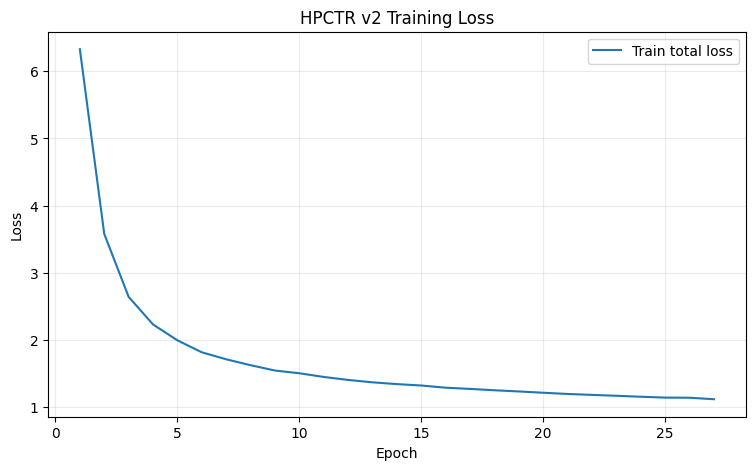

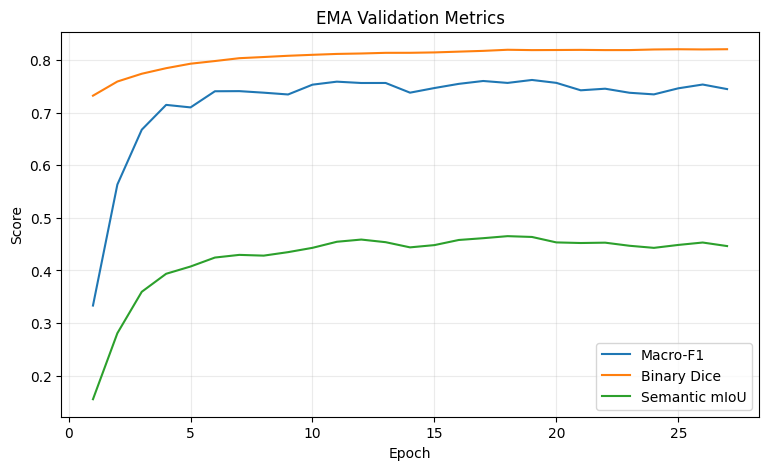

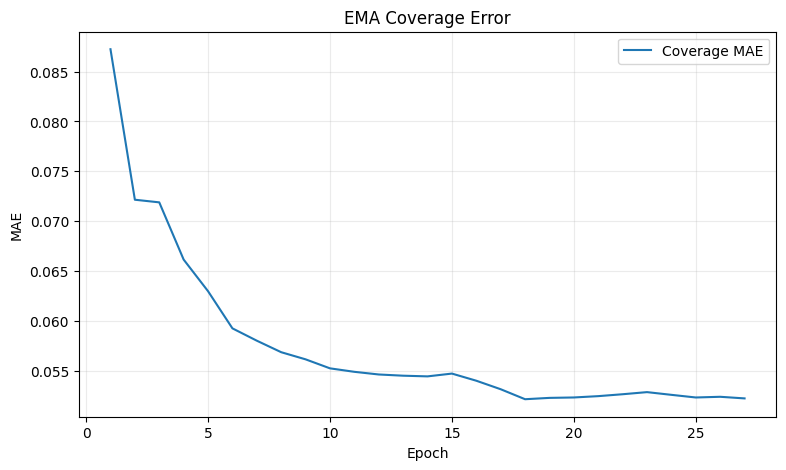

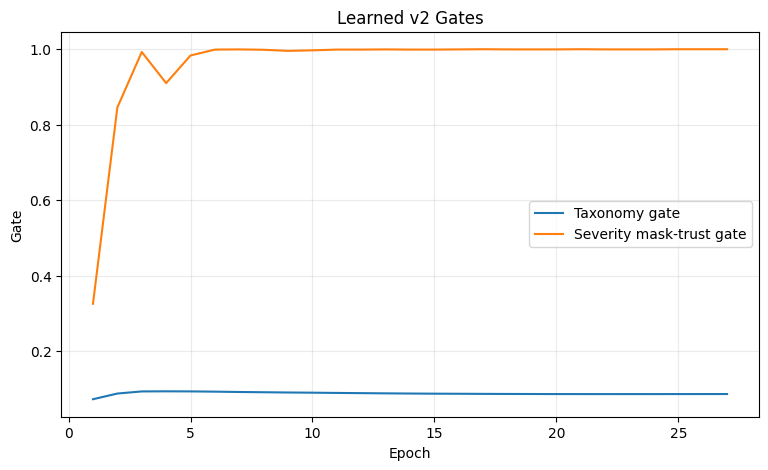

In [15]:
# 13. Curves
hist=pd.DataFrame(history); display(hist.tail())
plt.figure(figsize=(9,5)); plt.plot(hist.epoch,hist.train_total,label='Train total loss'); plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('HPCTR v2 Training Loss'); plt.grid(alpha=.25); plt.legend(); plt.show()
plt.figure(figsize=(9,5)); plt.plot(hist.epoch,hist.val_combo_macro_f1,label='Macro-F1'); plt.plot(hist.epoch,hist.val_binary_dice,label='Binary Dice'); plt.plot(hist.epoch,hist.val_semantic_miou_disease,label='Semantic mIoU'); plt.xlabel('Epoch'); plt.ylabel('Score'); plt.title('EMA Validation Metrics'); plt.legend(); plt.grid(alpha=.25); plt.show()
plt.figure(figsize=(9,5)); plt.plot(hist.epoch,hist.val_severity_mae,label='Coverage MAE'); plt.xlabel('Epoch'); plt.ylabel('MAE'); plt.title('EMA Coverage Error'); plt.grid(alpha=.25); plt.legend(); plt.show()
plt.figure(figsize=(9,5)); plt.plot(hist.epoch,hist.taxonomy_gate,label='Taxonomy gate'); plt.plot(hist.epoch,hist.severity_gate,label='Severity mask-trust gate'); plt.xlabel('Epoch'); plt.ylabel('Gate'); plt.title('Learned v2 Gates'); plt.grid(alpha=.25); plt.legend(); plt.show()


In [16]:
# 14. Final untouched test-set result
ckpt=torch.load(best_path,map_location=DEVICE,weights_only=False); model.load_state_dict(ckpt['model'],strict=True); model.eval()
print(f"Loaded best EMA checkpoint from epoch {ckpt['epoch']}",flush=True)

test_metrics,pred_df,semantic_conf=evaluate(model,test_loader,True,show_progress=True,desc='Final TEST single-view EMA',tta=False)
tta_metrics=evaluate(model,test_loader,False,show_progress=True,desc='Final TEST flip-TTA EMA',tta=True)
metric_names=['115-class Accuracy','115-class Macro-F1','115-class Macro-Precision','115-class Macro-Recall','Host Accuracy','Disease-type Accuracy',
              'Binary Lesion IoU (micro)','Binary Lesion Dice (micro)','Binary Lesion IoU (mean image)','Binary Lesion Dice (mean image)',
              'Factorized Semantic mIoU','Factorized Semantic mAcc','Coverage MAE','Coverage RMSE','Coverage R2','Coverage Pearson r','Coverage Spearman rho']
metric_keys=['combo_accuracy','combo_macro_f1','combo_macro_precision','combo_macro_recall','host_accuracy','disease_accuracy','binary_iou','binary_dice',
             'binary_iou_image_macro','binary_dice_image_macro','semantic_miou_disease','semantic_macc_disease','severity_mae','severity_rmse','severity_r2','severity_pearson','severity_spearman']
result_table=pd.DataFrame({'Metric':metric_names,'Primary_SingleView_EMA':[test_metrics[k] for k in metric_keys],'Secondary_FlipTTA_EMA':[tta_metrics[k] for k in metric_keys]})
display(result_table.style.format({'Primary_SingleView_EMA':'{:.4f}','Secondary_FlipTTA_EMA':'{:.4f}'}))
result_table.to_csv(Path(cfg.output_dir)/'final_test_metrics_v2.csv',index=False)
pred_df.to_csv(Path(cfg.output_dir)/'test_predictions_v2_singleview.csv',index=False); np.save(Path(cfg.output_dir)/'semantic_confusion_matrix_v2.npy',semantic_conf)
with open(Path(cfg.output_dir)/'test_metrics_singleview.json','w') as f: json.dump({k:float(v) for k,v in test_metrics.items()},f,indent=2)
with open(Path(cfg.output_dir)/'test_metrics_tta.json','w') as f: json.dump({k:float(v) for k,v in tta_metrics.items()},f,indent=2)
print('\nPRIMARY single-view EMA is the fair-comparison result.',flush=True)


Loaded best EMA checkpoint from epoch 18


Final TEST single-view EMA:   0%|          | 0/1148 [00:00<?, ?it/s]

Final TEST flip-TTA EMA:   0%|          | 0/1148 [00:00<?, ?it/s]

,Metric,Primary_SingleView_EMA,Secondary_FlipTTA_EMA
0,115-class Accuracy,0.8192,0.8196
1,115-class Macro-F1,0.7519,0.7509
2,115-class Macro-Precision,0.7707,0.7624
3,115-class Macro-Recall,0.7521,0.7522
4,Host Accuracy,0.8854,0.8871
5,Disease-type Accuracy,0.8684,0.8754
6,Binary Lesion IoU (micro),0.7132,0.7175
7,Binary Lesion Dice (micro),0.8326,0.8355
8,Binary Lesion IoU (mean image),0.6627,0.6673
9,Binary Lesion Dice (mean image),0.7684,0.7719



PRIMARY single-view EMA is the fair-comparison result.


In [17]:
# 15. Head / medium / tail behavior of PRIMARY single-view EMA
counts=np.array([c for c in combo_counts if c>0]); q1,q2=np.quantile(counts,[1/3,2/3])
def group(c):
    n=combo_counts[int(c)]; return 'Tail' if n<=q1 else ('Medium' if n<=q2 else 'Head')
pred_df['frequency_group']=pred_df.true_combo.map(group); pred_df['correct']=(pred_df.true_combo==pred_df.pred_combo).astype(int)
rows=[]
for g,s in pred_df.groupby('frequency_group'):
    labs=sorted(s.true_combo.unique()); rows.append({'Group':g,'N':len(s),'Accuracy':s.correct.mean(),'Macro-F1':f1_score(s.true_combo,s.pred_combo,labels=labs,average='macro',zero_division=0),
        'Mean image lesion IoU':s.image_binary_iou.mean(),'Mean image lesion Dice':s.image_binary_dice.mean(),'Coverage MAE':mean_absolute_error(s.true_severity,s.pred_severity)})
group_table=pd.DataFrame(rows).set_index('Group').reindex(['Head','Medium','Tail']).reset_index()
display(group_table.style.format({'Accuracy':'{:.4f}','Macro-F1':'{:.4f}','Mean image lesion IoU':'{:.4f}','Mean image lesion Dice':'{:.4f}','Coverage MAE':'{:.4f}'}))
group_table.to_csv(Path(cfg.output_dir)/'head_medium_tail_results_v2.csv',index=False)


,Group,N,Accuracy,Macro-F1,Mean image lesion IoU,Mean image lesion Dice,Coverage MAE
0,Head,1395,0.8659,0.8711,0.6823,0.7853,0.0427
1,Medium,626,0.7812,0.8081,0.6312,0.7440,0.0603
2,Tail,274,0.6679,0.6864,0.6346,0.7385,0.0611


In [18]:
# 15.5 Class-wise long-tail diagnostics for PRIMARY single-view EMA
c = semantic_conf.astype(float)
inter = np.diag(c)
union = c.sum(1) + c.sum(0) - inter
support = c.sum(1)

rows = []
for combo_idx in range(115):
    sem_idx = combo_idx + 1
    true_sub = pred_df[pred_df.true_combo == combo_idx]
    cls_recall = float((true_sub.pred_combo == combo_idx).mean()) if len(true_sub) else np.nan
    class_iou = float(inter[sem_idx] / max(union[sem_idx], 1.0))
    class_acc = float(inter[sem_idx] / max(support[sem_idx], 1.0))
    rows.append({
        'combo_id': combo_idx,
        'combo_name': COMBO_NAMES[combo_idx],
        'train_images': int(combo_counts[combo_idx]),
        'test_images': int(len(true_sub)),
        'classification_recall': cls_recall,
        'semantic_iou': class_iou,
        'semantic_pixel_accuracy': class_acc
    })

classwise_df = pd.DataFrame(rows)
classwise_df.to_csv(Path(cfg.output_dir)/'classwise_results_v2.csv', index=False)

valid_iou = classwise_df.semantic_iou.notna()
freq_iou_rho = spearmanr(
    classwise_df.loc[valid_iou, 'train_images'],
    classwise_df.loc[valid_iou, 'semantic_iou']
).statistic
freq_cls_rho = spearmanr(
    classwise_df.train_images,
    classwise_df.classification_recall
).statistic

print(f'Spearman(train frequency, semantic IoU) = {freq_iou_rho:.4f}', flush=True)
print(f'Spearman(train frequency, classification recall) = {freq_cls_rho:.4f}', flush=True)

print('\nLowest semantic-IoU classes:')
display(classwise_df.sort_values('semantic_iou').head(15))

print('\nHighest semantic-IoU classes:')
display(classwise_df.sort_values('semantic_iou',ascending=False).head(15))

# WHAT-vs-WHERE decomposition diagnostic.
pred_df['class_correct'] = pred_df.true_combo == pred_df.pred_combo
what_where = pred_df.groupby('class_correct').agg(
    N=('filename','size'),
    mean_binary_iou=('image_binary_iou','mean'),
    mean_binary_dice=('image_binary_dice','mean'),
    coverage_mae=('true_severity', lambda s: np.nan)
).reset_index()

# Compute coverage MAE explicitly per group.
ww_rows=[]
for flag,sub in pred_df.groupby('class_correct'):
    ww_rows.append({
        'Class prediction correct': bool(flag),
        'N': len(sub),
        'Mean image lesion IoU': sub.image_binary_iou.mean(),
        'Mean image lesion Dice': sub.image_binary_dice.mean(),
        'Coverage MAE': mean_absolute_error(sub.true_severity,sub.pred_severity)
    })
what_where = pd.DataFrame(ww_rows)
display(what_where.style.format({
    'Mean image lesion IoU':'{:.4f}',
    'Mean image lesion Dice':'{:.4f}',
    'Coverage MAE':'{:.4f}'
}))
what_where.to_csv(Path(cfg.output_dir)/'what_where_error_analysis_v2.csv',index=False)


Spearman(train frequency, semantic IoU) = 0.3672
Spearman(train frequency, classification recall) = 0.3523

Lowest semantic-IoU classes:


,combo_id,combo_name,train_images,test_images,classification_recall,semantic_iou,semantic_pixel_accuracy
16,16,bell pepper frogeye leaf spot,21,6,0.000000,0.000000,0.000000
41,41,coffee black rot,5,1,0.000000,0.000000,0.000000
70,70,plum bacterial spot,11,3,0.000000,0.000000,0.000000
32,32,cauliflower alternaria leaf spot,37,11,0.090909,0.007208,0.012666
25,25,broccoli ring spot,11,3,0.333333,0.024148,0.141670
94,94,tobacco frogeye leaf spot,19,6,0.166667,0.030719,0.090982
26,26,cabbage alternaria leaf spot,41,13,0.153846,0.058341,0.088036
53,53,eggplant phytophthora blight,22,7,0.285714,0.108041,0.124979
57,57,ginger sheath blight,46,14,0.357143,0.117612,0.190000
12,12,bean mosaic virus,40,12,0.250000,0.120980,0.160893



Highest semantic-IoU classes:


,combo_id,combo_name,train_images,test_images,classification_recall,semantic_iou,semantic_pixel_accuracy
68,68,peach rust,5,2,1.000000,0.889470,0.913431
8,8,banana cordana leaf spot,38,11,0.909091,0.859778,0.902207
80,80,raspberry yellow rust,26,7,0.857143,0.834727,0.963400
47,47,corn smut,140,40,0.975000,0.833942,0.906317
15,15,bell pepper blossom end rot,78,22,1.000000,0.830118,0.892432
66,66,peach brown rot,120,35,0.914286,0.819228,0.909007
5,5,banana black leaf streak,116,33,0.969697,0.819044,0.909439
106,106,wheat loose smut,149,43,1.000000,0.817725,0.917824
71,71,plum brown rot,56,16,0.937500,0.784193,0.916205
18,18,blueberry anthracnose,29,8,1.000000,0.779431,0.879586


,Class prediction correct,N,Mean image lesion IoU,Mean image lesion Dice,Coverage MAE
0,False,415,0.5844,0.6963,0.0828
1,True,1880,0.6799,0.7844,0.0424


In [19]:
# 15.6 Coverage-band and real HPCTR internal-behaviour analysis
# Descriptive coverage bands only; these are NOT agronomic severity grades.
pred_df['coverage_band'] = pd.cut(
    pred_df.true_severity,
    bins=[-1e-9,0.10,0.30,1.0],
    labels=['Low coverage <=10%','Medium coverage 10-30%','High coverage >30%']
)

band_rows=[]
for band,sub in pred_df.groupby('coverage_band',observed=True):
    band_rows.append({
        'Coverage band': str(band),
        'N': len(sub),
        'Classification Accuracy': (sub.true_combo==sub.pred_combo).mean(),
        'Mean image lesion IoU': sub.image_binary_iou.mean(),
        'Coverage MAE': mean_absolute_error(sub.true_severity,sub.pred_severity)
    })
coverage_band_table=pd.DataFrame(band_rows)
display(coverage_band_table.style.format({
    'Classification Accuracy':'{:.4f}',
    'Mean image lesion IoU':'{:.4f}',
    'Coverage MAE':'{:.4f}'
}))
coverage_band_table.to_csv(Path(cfg.output_dir)/'coverage_band_results_v2.csv',index=False)

# Measure router/gate behaviour on REAL test images rather than a random probe.
model.eval(); total_n=0; route_sum=torch.zeros(3,device=DEVICE); sev_gates=[]; uncertainties=[]
with torch.no_grad():
    bar=tqdm(test_loader,total=len(test_loader),desc='HPCTR internal analysis',dynamic_ncols=True,leave=False)
    for batch in bar:
        x=batch['image'].to(DEVICE,non_blocking=True)
        with torch.amp.autocast(device_type=DEVICE.type,enabled=AMP_ENABLED): out=model(x)
        bs=x.size(0); route_sum += out['route_usage']*bs; total_n += bs
        sev_gates.extend(out['severity_gate'].float().cpu().tolist())
        uncertainties.extend(out['mask_uncertainty'].float().cpu().tolist())

real_route=(route_sum/max(total_n,1)).cpu().numpy()
internal_stats={
    'route_identity_mean':float(real_route[0]),
    'route_lesion_mean':float(real_route[1]),
    'route_severity_mean':float(real_route[2]),
    'severity_gate_mean':float(np.mean(sev_gates)),
    'severity_gate_std':float(np.std(sev_gates)),
    'mask_uncertainty_mean':float(np.mean(uncertainties)),
    'mask_uncertainty_std':float(np.std(uncertainties))
}
print(json.dumps(internal_stats,indent=2),flush=True)
with open(Path(cfg.output_dir)/'hpctr_internal_stats_v2.json','w') as f: json.dump(internal_stats,f,indent=2)


,Coverage band,N,Classification Accuracy,Mean image lesion IoU,Coverage MAE
0,Low coverage <=10%,930,0.8280,0.5632,0.0306
1,Medium coverage 10-30%,800,0.8387,0.6899,0.0472
2,High coverage >30%,565,0.7770,0.7877,0.0846


HPCTR internal analysis:   0%|          | 0/1148 [00:00<?, ?it/s]

{
  "route_identity_mean": 0.41697412729263306,
  "route_lesion_mean": 0.3620787262916565,
  "route_severity_mean": 0.2209470123052597,
  "severity_gate_mean": 0.941501034007353,
  "severity_gate_std": 0.15673461144707818,
  "mask_uncertainty_mean": 0.13770854575255143,
  "mask_uncertainty_std": 0.12064252185171458
}


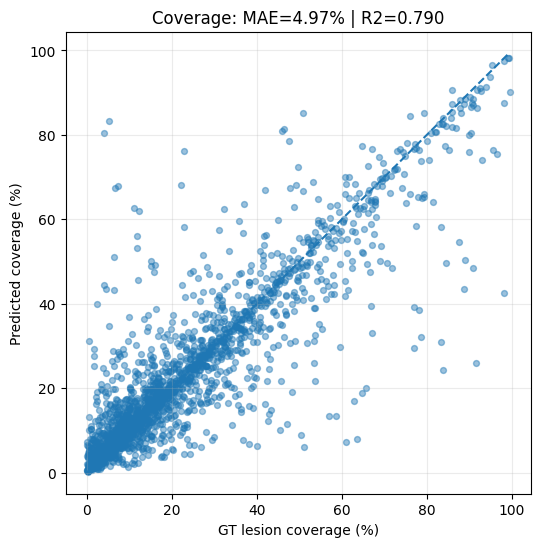

In [20]:

# 16. Coverage plot
plt.figure(figsize=(6,6)); plt.scatter(pred_df.true_severity*100,pred_df.pred_severity*100,alpha=.45,s=18)
lo=min(pred_df.true_severity.min(),pred_df.pred_severity.min())*100; hi=max(pred_df.true_severity.max(),pred_df.pred_severity.max())*100
plt.plot([lo,hi],[lo,hi],'--'); plt.xlabel('GT lesion coverage (%)'); plt.ylabel('Predicted coverage (%)'); plt.title(f"Coverage: MAE={test_metrics['severity_mae']*100:.2f}% | R2={test_metrics['severity_r2']:.3f}"); plt.grid(alpha=.25); plt.show()


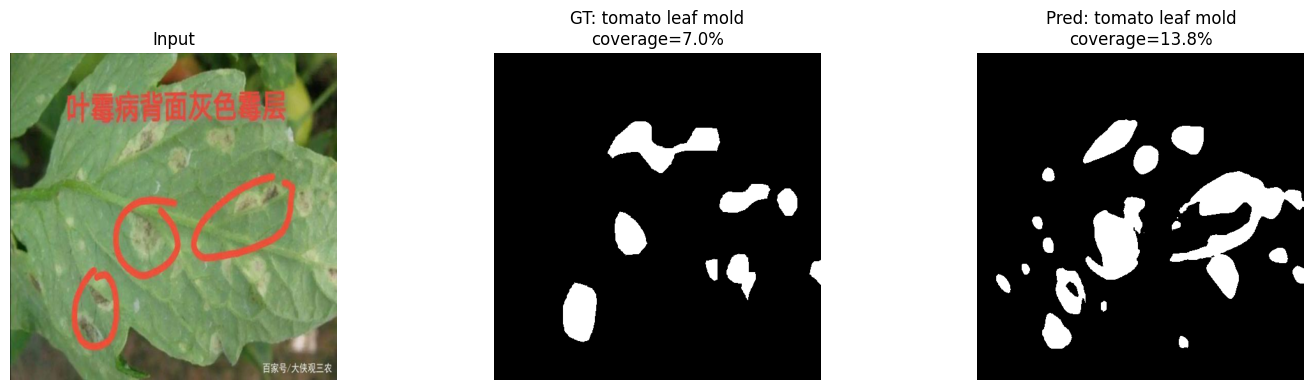

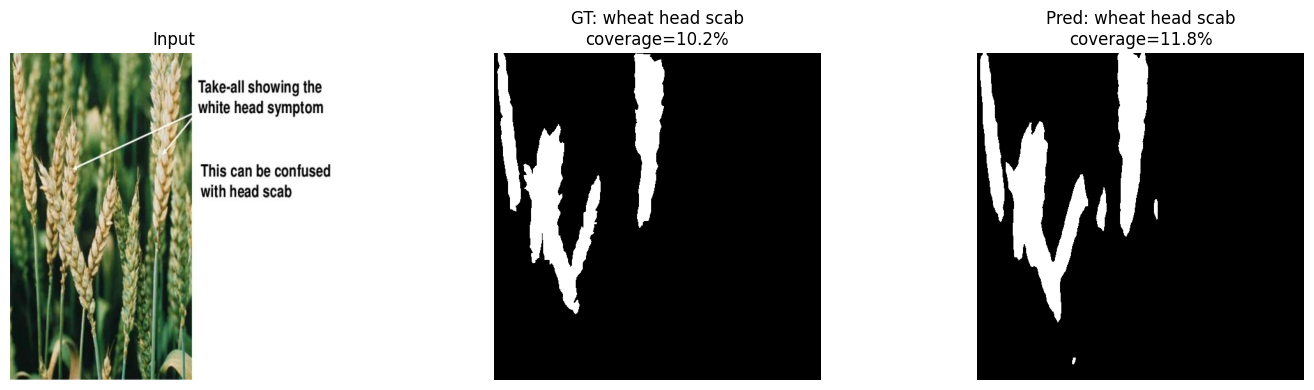

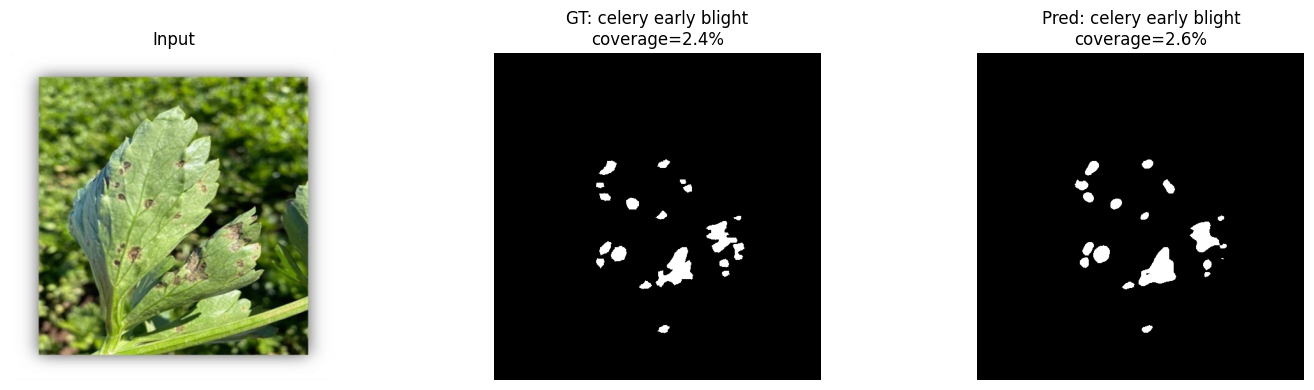

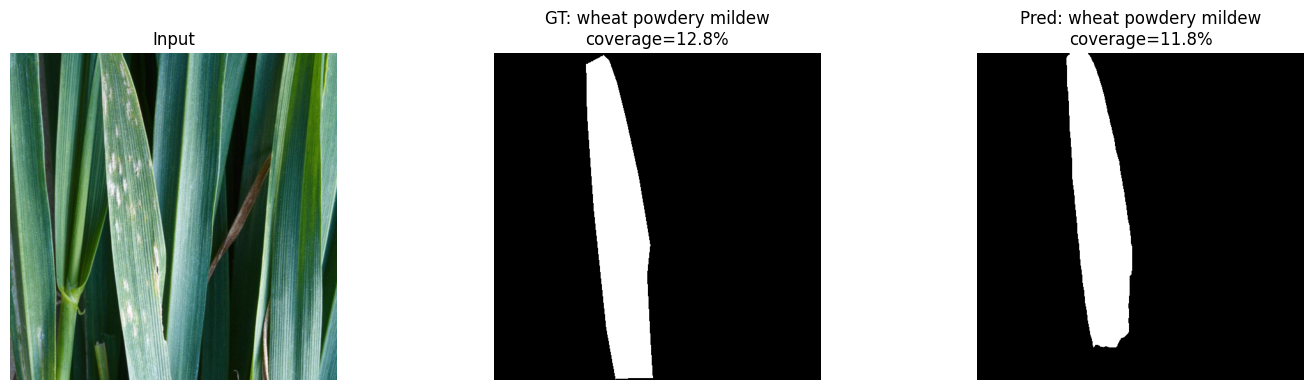

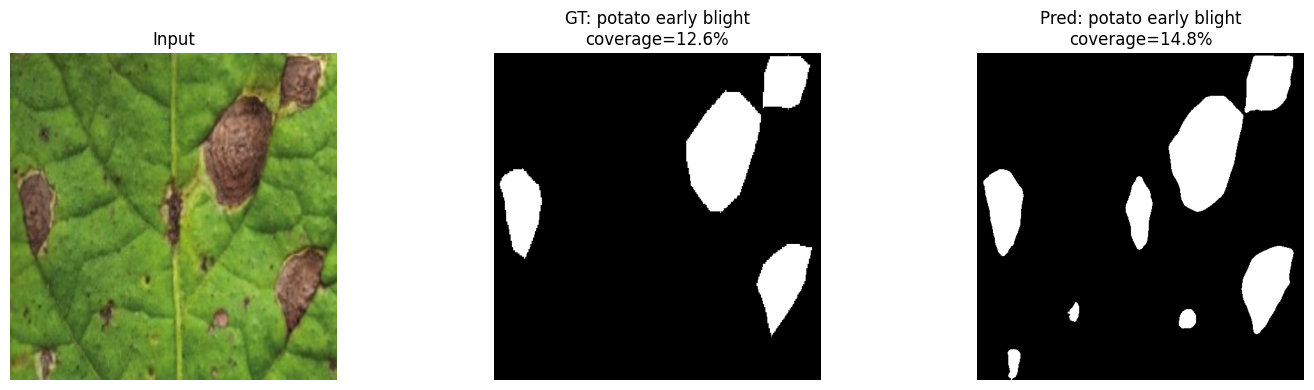

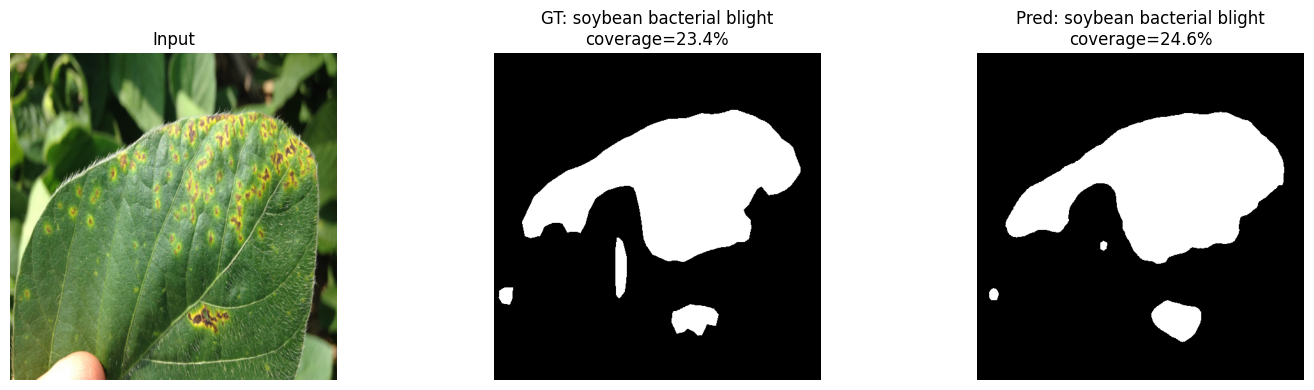

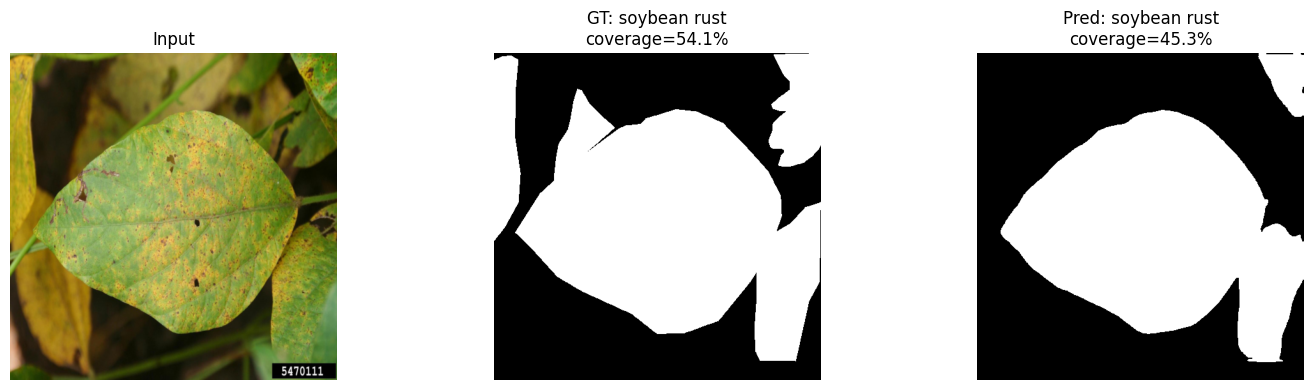

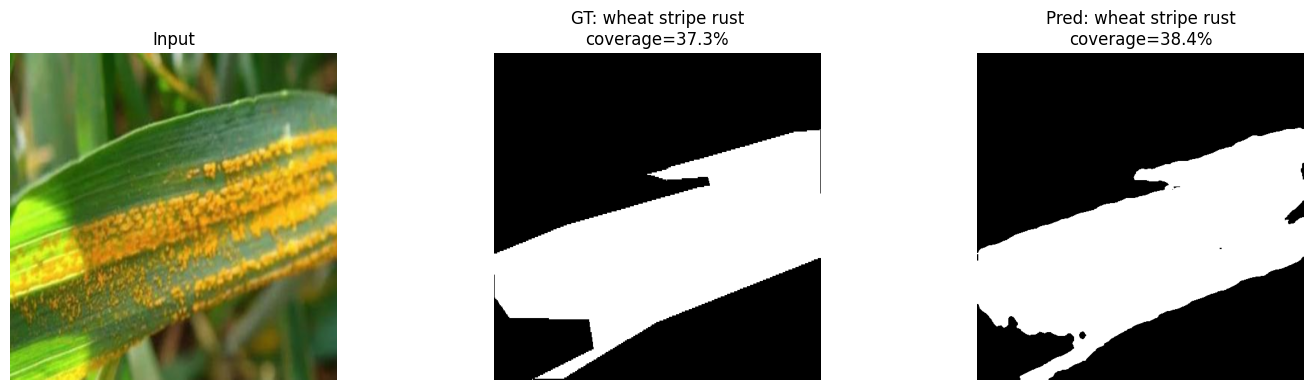

In [21]:

# 17. Qualitative predictions
@torch.no_grad()
def visualize(model,dataset,n=8,seed=7):
    ids=np.random.default_rng(seed).choice(len(dataset),size=min(n,len(dataset)),replace=False)
    mean=torch.tensor(IMAGENET_MEAN)[:,None,None]; std=torch.tensor(IMAGENET_STD)[:,None,None]
    for idx in ids:
        s=dataset[idx]; x=s['image'][None].to(DEVICE); out=model(x); pc=int(out['combo_logits'].argmax(1)); pm=(torch.sigmoid(out['lesion_logits'])[0,0]>=.5).cpu().numpy(); gm=s['mask'][0].numpy()
        img=(s['image']*std+mean).clamp(0,1).permute(1,2,0).numpy(); tc=int(s['combo']); ts=float(s['severity']); ps=float(out['severity'])
        plt.figure(figsize=(15,4)); plt.subplot(1,3,1); plt.imshow(img); plt.axis('off'); plt.title('Input')
        plt.subplot(1,3,2); plt.imshow(gm,cmap='gray'); plt.axis('off'); plt.title(f'GT: {COMBO_NAMES[tc]}\ncoverage={ts*100:.1f}%')
        plt.subplot(1,3,3); plt.imshow(pm,cmap='gray'); plt.axis('off'); plt.title(f'Pred: {COMBO_NAMES[pc]}\ncoverage={ps*100:.1f}%'); plt.tight_layout(); plt.show()
visualize(model,test_ds,8)


In [22]:
# 18. Parameters, latency, final summary
params_m=sum(p.numel() for p in model.parameters())/1e6; latency_ms=fps=np.nan
if DEVICE.type=='cuda':
    dummy=torch.randn(1,3,cfg.image_size,cfg.image_size,device=DEVICE); model.eval()
    with torch.no_grad():
        for _ in range(10):
            with torch.amp.autocast(device_type=DEVICE.type,enabled=AMP_ENABLED): model(dummy)
    torch.cuda.synchronize(); times=[]
    with torch.no_grad():
        for _ in range(50):
            t=time.perf_counter()
            with torch.amp.autocast(device_type=DEVICE.type,enabled=AMP_ENABLED): probe_out=model(dummy)
            torch.cuda.synchronize(); times.append((time.perf_counter()-t)*1000)
    latency_ms=float(np.median(times)); fps=1000/latency_ms; ru=probe_out['route_usage'].cpu().numpy().tolist(); tax=float(probe_out['taxonomy_gate'].cpu()); sg=float(probe_out['severity_gate'].mean().cpu())
    del dummy,probe_out
else: ru=[np.nan]*3; tax=sg=np.nan
summary={'best_epoch':int(ckpt['epoch']),'PRIMARY_singleview':{k:float(test_metrics[k]) for k in ['combo_accuracy','combo_macro_f1','binary_iou','binary_dice','binary_iou_image_macro','semantic_miou_disease','semantic_macc_disease','severity_mae','severity_rmse','severity_r2','severity_pearson']},
         'SECONDARY_flipTTA':{k:float(tta_metrics[k]) for k in ['combo_accuracy','combo_macro_f1','semantic_miou_disease','severity_mae','severity_r2']},
         'parameters_m':float(params_m),'latency_ms_singleview':None if np.isnan(latency_ms) else float(latency_ms),'fps_singleview':None if np.isnan(fps) else float(fps),
         'taxonomy_gate_probe':tax,'severity_gate_probe':sg,'hpctr_route_identity_probe':float(ru[0]),'hpctr_route_lesion_probe':float(ru[1]),'hpctr_route_severity_probe':float(ru[2])}
with open(Path(cfg.output_dir)/'result_summary_v2.json','w') as f: json.dump(summary,f,indent=2)
print(json.dumps(summary,indent=2),flush=True); print('\nSaved:',flush=True)
for p in sorted(Path(cfg.output_dir).glob('*')): print(' -',p.name,flush=True)


{
  "best_epoch": 18,
  "PRIMARY_singleview": {
    "combo_accuracy": 0.8191721132897604,
    "combo_macro_f1": 0.7518893608884893,
    "binary_iou": 0.7132470138133863,
    "binary_dice": 0.8326260113838739,
    "binary_iou_image_macro": 0.6626538705973589,
    "semantic_miou_disease": 0.4800164702229558,
    "semantic_macc_disease": 0.639054387916377,
    "severity_mae": 0.04968682805520788,
    "severity_rmse": 0.09508218768352322,
    "severity_r2": 0.7901029927215597,
    "severity_pearson": 0.8904212393144204
  },
  "SECONDARY_flipTTA": {
    "combo_accuracy": 0.8196078431372549,
    "combo_macro_f1": 0.7509001886363396,
    "semantic_miou_disease": 0.48356657839824213,
    "severity_mae": 0.04933438565663388,
    "severity_r2": 0.7932431208431858
  },
  "parameters_m": 30.145466,
  "latency_ms_singleview": 16.64809900103137,
  "fps_singleview": 60.0669181471139,
  "taxonomy_gate_probe": 0.08601228147745132,
  "severity_gate_probe": 0.1195068359375,
  "hpctr_route_identity_probe"